In [12]:
%pip install -q  pyLDAvis

In [1]:
# If needed, uncomment and run:
# %pip install -q pandas numpy matplotlib seaborn nltk wordcloud scikit-learn pyLDAvis

import re
import json
import glob
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

RANDOM_STATE = 42


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [2]:
REPO_API = "https://api.github.com/repos/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/contents"

try:
    with urllib.request.urlopen(REPO_API, timeout=20) as response:
        repo_items = json.loads(response.read().decode("utf-8"))
    data_files = [
        item for item in repo_items
        if item.get("type") == "file"
        and item.get("name", "").lower().endswith((".csv", ".json"))
    ]
    print("Available dataset files:")
    for item in data_files:
        print(item["name"], "->", item["download_url"])
except Exception as exc:
    data_files = []
    print("Could not list repository files automatically:", exc)

# Uses the first CSV/JSON in the repository root, or a local CSV/JSON if available.
DATA_PATH = None
if data_files:
    selected_file = data_files[0]
    DATA_PATH = selected_file["name"]
    urllib.request.urlretrieve(selected_file["download_url"], DATA_PATH)
    print("Downloaded:", DATA_PATH)
else:
    local_files = glob.glob("*.csv") + glob.glob("*.json")
    if local_files:
        DATA_PATH = local_files[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "Download a CSV/JSON file from the assignment GitHub repository and upload it to the notebook, "
        "then set DATA_PATH to its filename."
    )

if DATA_PATH.lower().endswith(".csv"):
    df = pd.read_csv(DATA_PATH)
else:
    df = pd.read_json(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Available dataset files:
Adult_Immunization_Features_Headlines.csv -> https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adult_Immunization_Features_Headlines.csv
Adult_Immunization_News_Headlines.csv -> https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adult_Immunization_News_Headlines.csv
Adverse_Drug_Events_Related_Headlines.csv -> https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adverse_Drug_Events_Related_Headlines.csv
Adverse_Drug_Reaction_Journals_Headlines.csv -> https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Adverse_Drug_Reaction_Journals_Headlines.csv
Adverse_Drug_Reaction_News_Headlines.csv -> https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-La

,Date,Source,Headlines,Teaser
0,October 2004,Medscape Infectious Diseases,"Infectious Diseases: October 30, 2004","Dr. Bartlett reviews the latest on influenza, ..."
1,July 2004,Journal of the American Board of Family Medicine,Influenza Vaccination in Pregnancy,Are enough family physicians and obstetricians...
2,June 2004,Medscape Nurses,Bacterial Meningitis: A Deadly But Preventable...,Those whose lives have been touched by this le...
3,April 2004,Alimentary Pharmacology & Therapeutics,Hepatitis Vaccination in Patients With Chronic...,Despite a declining incidence of acute viral h...
4,November 2003,Medscape Infectious Diseases,Emerging Infections,Dr. John Bartlett reports on the latest data f...


In [3]:
text_candidates = [
    col for col in df.columns
    if any(key in str(col).lower() for key in
           ["headline", "title", "teaser", "text", "content", "description"])
]
object_columns = df.select_dtypes(include="object").columns.tolist()

if not object_columns:
    raise ValueError("No text column found. Check the dataset format.")

TEXT_COLUMN = text_candidates[0] if text_candidates else object_columns[0]
print("Selected text column:", TEXT_COLUMN)
display(df[TEXT_COLUMN].dropna().head())


Selected text column: Headlines


,Headlines
0,"Infectious Diseases: October 30, 2004"
1,Influenza Vaccination in Pregnancy
2,Bacterial Meningitis: A Deadly But Preventable...
3,Hepatitis Vaccination in Patients With Chronic...
4,Emerging Infections


In [4]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\\s]", " ", text)
    tokens = word_tokenize(text)
    return [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]

df["clean_tokens"] = df[TEXT_COLUMN].fillna("").apply(clean_text)
df["cleaned_text"] = df["clean_tokens"].apply(lambda tokens: " ".join(tokens))
display(df[[TEXT_COLUMN, "cleaned_text"]].head(10))


,Headlines,cleaned_text
0,"Infectious Diseases: October 30, 2004",infectious disease october
1,Influenza Vaccination in Pregnancy,influenza vaccination pregnancy
2,Bacterial Meningitis: A Deadly But Preventable...,bacterial meningitis deadly preventable disease
3,Hepatitis Vaccination in Patients With Chronic...,hepatitis vaccination patient chronic liver di...
4,Emerging Infections,emerging infection
5,"New Organisms, New Drugs, New Tests, New Guide...",new organism new drug new test new guideline r...
6,Asthma and Influenza Vaccination,asthma influenza vaccination
7,Some Answers to Smallpox Vaccination Questions,answer smallpox vaccination question
8,Flu Vaccine for Cardiovascular Prevention in t...,flu vaccine cardiovascular prevention elderly
9,October 2002,october


In [5]:
all_tokens = [token for tokens in df["clean_tokens"] for token in tokens]
word_freq = Counter(all_tokens)

freq_df = pd.DataFrame(word_freq.most_common(20), columns=["Word", "Frequency"])
print("Unique cleaned words:", len(word_freq))
print("Total cleaned tokens:", len(all_tokens))
display(freq_df)


Unique cleaned words: 793
Total cleaned tokens: 1925


,Word,Frequency
0,vaccine,116
1,influenza,77
2,flu,47
3,vaccination,38
4,new,32
5,adult,29
6,patient,28
7,hpv,27
8,disease,26
9,recommendation,20


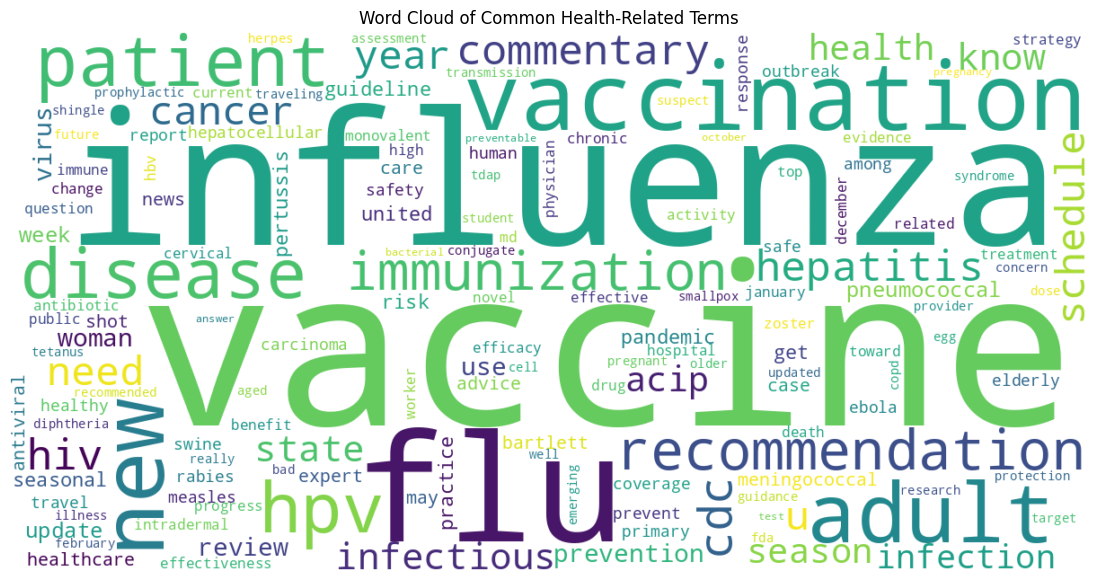

In [6]:
wordcloud = WordCloud(
    width=1200, height=600, background_color="white", max_words=150
).generate_from_frequencies(word_freq)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Common Health-Related Terms")
plt.show()


In [7]:
documents = df["cleaned_text"].fillna("").tolist()

vectorizer = CountVectorizer(max_df=0.95, min_df=2, max_features=5000)
doc_term_matrix = vectorizer.fit_transform(documents)
print("Document-term matrix shape:", doc_term_matrix.shape)


Document-term matrix shape: (366, 261)


In [8]:
N_TOPICS = 5

lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    learning_method="batch",
    max_iter=10
)
lda.fit(doc_term_matrix)
feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-5:][::-1]
    print(f"Topic {topic_idx + 1}: " + ", ".join(feature_names[i] for i in top_indices))


Topic 1: influenza, vaccine, vaccination, hepatitis, hpv
Topic 2: vaccine, hpv, flu, patient, hiv
Topic 3: influenza, vaccination, recommendation, disease, health
Topic 4: flu, state, vaccine, united, influenza
Topic 5: adult, new, immunization, disease, schedule


In [13]:
import pyLDAvis
import pyLDAvis.lda_model

vis = pyLDAvis.lda_model.prepare(
    lda, doc_term_matrix, vectorizer, mds="pcoa"
)
pyLDAvis.display(vis)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
